In [2]:
import geopandas as gpd
import pandas as pd

# Chargement des couches
gdf_antenne = gpd.read_file("projet_telecom.gpkg", layer="antenne")
provinces = gpd.read_file("projet_telecom.gpkg", layer="provinces")

# Vérification rapide des CRS
print(gdf_antenne.crs)
print(provinces.crs)

EPSG:4326
EPSG:4326


In [3]:
# 1. Jointure spatiale (avec les données en 4326)

antennes_par_province = gpd.sjoin(gdf_antenne, provinces, how="inner", predicate="within")
df_antennes_par_province = antennes_par_province.groupby('NAME_1').size().reset_index(name='Nombre_Antennes')

print("nombres d'anntenne dans le fichier original : ", len(gdf_antenne))
print("nombres d'anntenne après jointure spatiale : ", len(antennes_par_province))
print("nombres d'antennes perdues : ", len(gdf_antenne) - len(antennes_par_province))
# 2. Calcul de la superficie (sur une copie en Albers)
provinces_proj = provinces.to_crs("+proj=aea +lat_1=20 +lat_2=-23 +lat_0=0 +lon_0=25 +x_0=0 +y_0=0 +datum=WGS84 +units=m +no_defs")
provinces_proj['Superficie_km2'] = provinces_proj.geometry.area / 1_000_000

# 3. Fusion des deux DataFrames
df_analyse = df_antennes_par_province.merge(provinces_proj[['NAME_1', 'Superficie_km2']], on='NAME_1', how='left')

# 4. Calcul de la densité
df_analyse['Densite_Antennes_km2'] = df_analyse['Nombre_Antennes'] / df_analyse['Superficie_km2']

nombres d'anntenne dans le fichier original :  18311
nombres d'anntenne après jointure spatiale :  18214
nombres d'antennes perdues :  97


In [4]:
# Compter le nombre d'antennes par province
df_antennes_par_province = antennes_par_province.groupby('NAME_1').size().reset_index(name='Nombre_Antennes')

# Trier par nombre d'antennes décroissant
df_antennes_par_province = df_antennes_par_province.sort_values(by='Nombre_Antennes', ascending=False)

print(df_antennes_par_province)

            NAME_1  Nombre_Antennes
4         Kinshasa            11139
0     Haut-Katanga             2935
9          Lualaba             1738
5    Kongo-Central             1292
10       Nord-Kivu              424
3   Kasaï-Oriental              317
2            Ituri              121
1        Haut-Uele              110
8           Lomami               73
7            Kwilu               56
6           Kwango                7
11        Sud-Kivu                1
12          Tshopo                1


In [5]:
# Créer un tableau de base avec TOUTES les provinces
df_analyse = provinces_proj[['NAME_1', 'Superficie_km2']].merge(
    df_antennes_par_province, on='NAME_1', how='left'
)
# Remplacer les valeurs manquantes (provinces sans antennes) par 0
df_analyse['Nombre_Antennes'] = df_analyse['Nombre_Antennes'].fillna(0)
# Calculer la densité
df_analyse['Densite_Antennes_km2'] = df_analyse['Nombre_Antennes'] / df_analyse['Superficie_km2']

In [6]:
# Charger la population depuis le GPKG
gdf_population = gpd.read_file("projet_telecom.gpkg", layer="population")

# Jointure spatiale : chaque point de population est associé à sa province
pop_par_province = gpd.sjoin(gdf_population, provinces, how="inner", predicate="within")

# Somme de la population (colonne Z) par province
pop_par_province = pop_par_province.groupby('NAME_1')['Z'].sum().reset_index(name='Population_Totale')

print(pop_par_province.head())

         NAME_1  Population_Totale
0      Bas-Uele       1.764851e+06
1  Haut-Katanga       1.265431e+07
2   Haut-Lomami       9.383976e+06
3     Haut-Uele       2.472163e+06
4         Ituri       7.240769e+06


In [7]:
# Fusionner avec notre tableau d'analyse (qui contient déjà les antennes)
df_analyse = df_analyse.merge(pop_par_province, on='NAME_1', how='left')

# Remplir les valeurs manquantes (si une province a 0 population)
df_analyse['Population_Totale'] = df_analyse['Population_Totale'].fillna(0)

In [9]:
import numpy as np
# Calcul du ratio

# On remplace les 0 dans Nombre_Antennes par NaN pour éviter la division par zéro
df_analyse['Ratio_Pop_Antenne'] = df_analyse['Population_Totale'] / df_analyse['Nombre_Antennes'].replace(0, np.nan)

# Trier par ratio décroissant (les provinces les plus sous-couvertes en premier)
df_analyse = df_analyse.sort_values(by='Ratio_Pop_Antenne', ascending=False)

# Afficher le résultat final
print(df_analyse[['NAME_1', 'Population_Totale', 'Nombre_Antennes', 'Ratio_Pop_Antenne', 'Densite_Antennes_km2']])

            NAME_1  Population_Totale  Nombre_Antennes  Ratio_Pop_Antenne  \
21        Sud-Kivu       7.283738e+06              1.0       7.283738e+06   
24          Tshopo       4.105673e+06              1.0       4.105673e+06   
11          Kwango       2.753002e+06              7.0       3.932860e+05   
12           Kwilu       5.242356e+06             56.0       9.361350e+04   
13          Lomami       4.882978e+06             73.0       6.689011e+04   
5            Ituri       7.240769e+06            121.0       5.984107e+04   
18       Nord-Kivu       1.087252e+07            424.0       2.564273e+04   
4        Haut-Uele       2.472163e+06            110.0       2.247421e+04   
8   Kasaï-Oriental       6.655395e+06            317.0       2.099494e+04   
2     Haut-Katanga       1.265431e+07           2935.0       4.311520e+03   
10   Kongo-Central       3.538776e+06           1292.0       2.738991e+03   
14         Lualaba       4.741020e+06           1738.0       2.727859e+03   

C:\Users\admin\AppData\Local\Temp\ipykernel_8828\1705636442.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Ratio_Pop_Antenne', y='NAME_1', data=df_graph, palette='Reds_r')


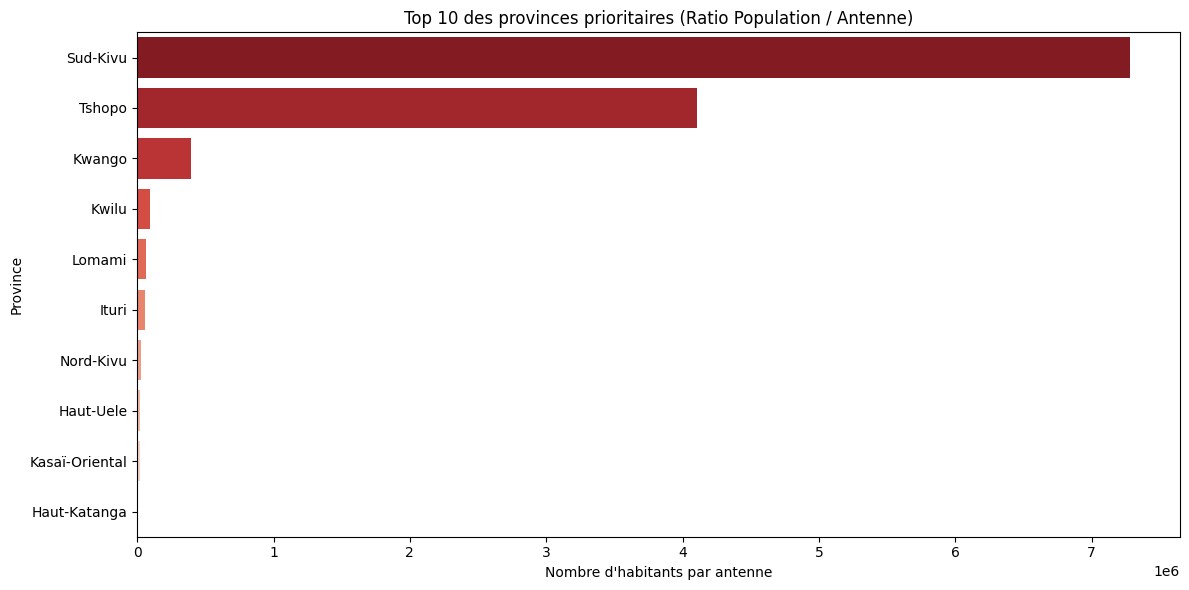

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrer les provinces sans antennes pour le graphique (sinon on a des NaN)
df_graph = df_analyse.dropna(subset=['Ratio_Pop_Antenne']).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x='Ratio_Pop_Antenne', y='NAME_1', data=df_graph, palette='Reds_r')
plt.title("Top 10 des provinces prioritaires (Ratio Population / Antenne)")
plt.xlabel("Nombre d'habitants par antenne")
plt.ylabel("Province")
plt.tight_layout()
plt.show()

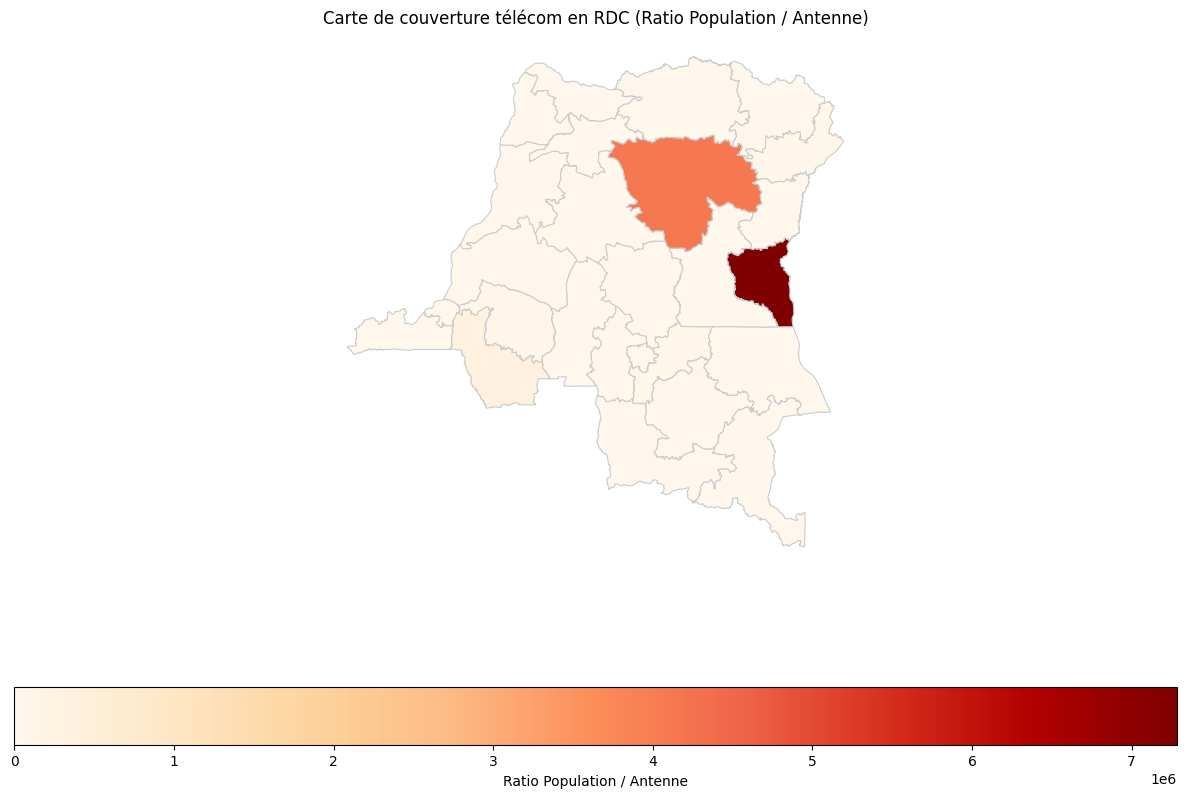

In [11]:
# Fusionner la géométrie des provinces avec nos données d'analyse
provinces_geo = provinces.merge(df_analyse, on='NAME_1', how='left')

# Remplir les NaN pour la carte (provinces sans antennes) avec une valeur très élevée ou 0
# Ici, on les met à 0 pour qu'elles apparaissent en gris/blanc sur la carte
provinces_geo['Ratio_Pop_Antenne'] = provinces_geo['Ratio_Pop_Antenne'].fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(15, 10))
provinces_geo.plot(
    column='Ratio_Pop_Antenne', 
    cmap='OrRd', 
    linewidth=0.8, 
    ax=ax, 
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "Ratio Population / Antenne", 'orientation': "horizontal"}
)
plt.title("Carte de couverture télécom en RDC (Ratio Population / Antenne)")
plt.axis('off')
plt.show()

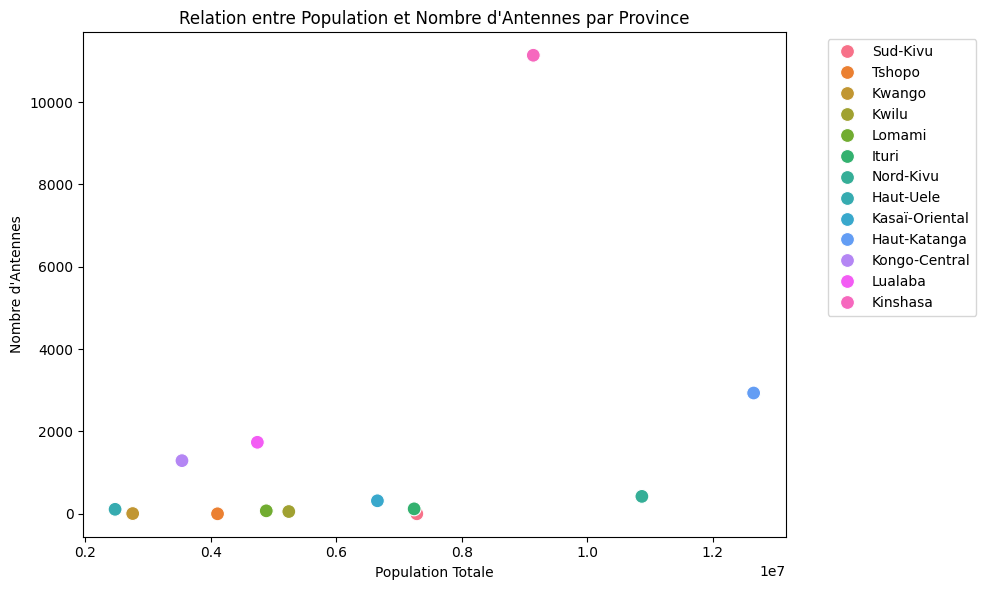

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Population_Totale', y='Nombre_Antennes', data=df_analyse.dropna(), hue='NAME_1', s=100)
plt.title("Relation entre Population et Nombre d'Antennes par Province")
plt.xlabel("Population Totale")
plt.ylabel("Nombre d'Antennes")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [13]:
provinces_final = provinces.merge(df_analyse, on='NAME_1', how='left')

provinces_final.to_file("projet_telecom.gpkg", layer="provinces_final", driver="GPKG")